# Simulación Montecarlo de impactos de rayo en el campus universitario
**Proyecto final – Computación Avanzada y Analítica**

En este proyecto se lanzan N puntos de impacto potencial uniformemente distribuidos sobre una región rectangular. Cada estructura tiene un radio de atracción proporcional a su altura Ra = c · h. Un punto impacta una estructura si cae dentro de su círculo de atracción; si cae en varios círculos, se asigna a la estructura de centro más cercano. La probabilidad relativa de impacto se estima como P_i = N_i / N, con error estándar σ = sqrt(P_i (1 − P_i) / N).

## 1. Parámetros editables

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros

LX, LY = 400.0, 400.0 # Dimensiones de la región (m)
C_COEF = 2.5          # Coeficiente del radio de atracción: Ra = c * h
N_PRINCIPAL = 10_000  # Número de puntos de la simulación principal
SEMILLA = 77          # Semilla aleatoria para que sea reproducible

# Lista de estructuras: (nombre, (x, y), altura h en m)
ESTRUCTURAS = [
    ("Bloque A",    (100.0, 250.0), 30.0),
    ("Bloque B",    (250.0, 250.0), 25.0),
    ("Bloque C",    (350.0, 250.0), 25.0),
    ("Lago",        (250.0, 350.0),  2.0),
    ("Parqueadero", (300.0, 150.0), 40.0),
]

# Variación 1: estructura a modificar y factor multiplicativo de su altura
ESTRUCTURA_VARIADA = "Bloque A"
FACTOR_ALTURA = 2.0

# Variación 2: valores de N para el estudio de convergencia
N_CONVERGENCIA = [100, 500, 1000, 5000, 10000, 50000]

## 2. Funciones auxiliares

In [2]:
def simular_montecarlo(Lx, Ly, estructuras, c, N, semilla):
    """
    Ejecuta la simulación Montecarlo y devuelve un diccionario con los resultados.

    Parámetros
    ----------
    Lx, Ly      : dimensiones de la región (m)
    estructuras : lista de (nombre, (x, y), altura)
    c           : coeficiente del radio de atracción (Ra = c * h)
    N           : número de puntos aleatorios
    semilla     : semilla del generador (default_rng)
    """
    rng = np.random.default_rng(semilla)

    # --- 1) Puntos de impacto potencial con distribución uniforme ---
    x = rng.uniform(0, Lx, N)
    y = rng.uniform(0, Ly, N)

    # --- 2) Datos de las estructuras como arreglos de NumPy ---
    nombres = [e[0] for e in estructuras]
    xs = np.array([e[1][0] for e in estructuras])
    ys = np.array([e[1][1] for e in estructuras])
    h  = np.array([e[2] for e in estructuras])
    Ra = c * h                                   # radio de atracción (m)

    # --- 3) Distancias al cuadrado: matriz (N puntos) x (n estructuras) ---
    d2 = (x[:, None] - xs[None, :])**2 + (y[:, None] - ys[None, :])**2

    # --- 4) Criterio de impacto: d^2 <= Ra^2 (se evita la raíz cuadrada) ---
    dentro = d2 <= Ra[None, :]**2

    # --- 5) Solapamientos: entre los círculos que contienen al punto,
    #        se elige el de centro más cercano (evita doble conteo) ---
    d2_validas = np.where(dentro, d2, np.inf)    # fuera de círculo -> infinito
    asignacion = np.argmin(d2_validas, axis=1)   # índice de la estructura elegida
    asignacion = np.where(dentro.any(axis=1), asignacion, -1)  # -1 = suelo

    # --- 6) Conteos, probabilidades y error estándar ---
    Ni = np.array([np.sum(asignacion == i) for i in range(len(estructuras))])
    P = Ni / N
    sigma = np.sqrt(P * (1 - P) / N)
    N_suelo = N - Ni.sum()
    P_suelo = 1 - P.sum()
    sigma_suelo = np.sqrt(P_suelo * (1 - P_suelo) / N)

    return dict(N=N, x=x, y=y, nombres=nombres, xs=xs, ys=ys, h=h, Ra=Ra,
                asignacion=asignacion, Ni=Ni, P=P, sigma=sigma,
                N_suelo=N_suelo, P_suelo=P_suelo, sigma_suelo=sigma_suelo)


def imprimir_tabla(res):
    """Imprime en consola la tabla de resultados (incluye la fila 'Suelo')."""
    print(f"{'Estructura':<14}{'Altura (m)':>11}{'Ra (m)':>9}{'Ni':>8}{'P_i':>10}{'sigma_Pi':>11}")
    print("-" * 63)
    for i, nom in enumerate(res["nombres"]):
        print(f"{nom:<14}{res['h'][i]:>11.1f}{res['Ra'][i]:>9.1f}{res['Ni'][i]:>8d}"
              f"{res['P'][i]:>10.4f}{res['sigma'][i]:>11.4f}")
    print(f"{'Suelo':<14}{'-':>11}{'-':>9}{res['N_suelo']:>8d}"
          f"{res['P_suelo']:>10.4f}{res['sigma_suelo']:>11.4f}")
    print("-" * 63)
    print(f"Total puntos: N = {res['N']}")


def _colores(n):
    """Un color distinto por estructura (paleta tab10)."""
    cmap = plt.get_cmap("tab10")
    return [cmap(i % 10) for i in range(n)]


def graficar_region(res, Lx, Ly, archivo="figura1_region_montecarlo.png"):
    """Gráfica 1: scatter de la región con círculos de atracción."""
    colores = _colores(len(res["nombres"]))
    fig, ax = plt.subplots(figsize=(8, 8))

    # Puntos que no impactaron ninguna estructura (suelo): gris claro, alpha bajo
    suelo = res["asignacion"] == -1
    ax.scatter(res["x"][suelo], res["y"][suelo], s=4, color="lightgray",
               alpha=0.4, label="Suelo")

    for i, nom in enumerate(res["nombres"]):
        m = res["asignacion"] == i
        ax.scatter(res["x"][m], res["y"][m], s=6, color=colores[i], alpha=0.7,
                   label=f"{nom} (Ra = {res['Ra'][i]:.0f} m)")
        # Círculo de atracción sin relleno, con borde del color de la estructura
        ax.add_patch(plt.Circle((res["xs"][i], res["ys"][i]), res["Ra"][i],
                                fill=False, edgecolor=colores[i], linewidth=2))
        # Centro de la estructura y su nombre
        ax.plot(res["xs"][i], res["ys"][i], marker="*", markersize=14,
                color=colores[i], markeredgecolor="black", zorder=5)
        ax.annotate(nom, (res["xs"][i], res["ys"][i]), textcoords="offset points",
                    xytext=(0, 9), ha="center", fontsize=9, fontweight="bold", zorder=6)

    ax.set_xlim(0, Lx); ax.set_ylim(0, Ly)
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
    ax.set_title("Simulación Montecarlo de impactos de rayo en el campus")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=8, markerscale=3)
    plt.axis("equal")
    fig.tight_layout()
    fig.savefig(archivo, dpi=150, bbox_inches="tight")
    plt.show()


def graficar_barras(res, archivo="figura2_probabilidad_por_zona.png"):
    """Gráfica 2: probabilidad por estructura y suelo con barras de error."""
    etiquetas = res["nombres"] + ["Suelo"]
    P = np.append(res["P"], res["P_suelo"])
    sig = np.append(res["sigma"], res["sigma_suelo"])
    colores = _colores(len(res["nombres"])) + ["lightgray"]

    fig, ax = plt.subplots(figsize=(9, 5))
    barras = ax.bar(etiquetas, P, yerr=sig, capsize=5, color=colores, edgecolor="black")
    # Valor numérico anotado sobre cada barra (encima de la barra de error)
    for b, p, s in zip(barras, P, sig):
        ax.annotate(f"{p:.4f}", (b.get_x() + b.get_width() / 2, p + s),
                    textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)
    ax.set_ylabel("Probabilidad estimada de impacto")
    ax.set_title(f"Probabilidad de impacto por zona (N = {res['N']})")
    ax.set_ylim(0, max(P + sig) * 1.15)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(archivo, dpi=150, bbox_inches="tight")
    plt.show()


def graficar_comparacion(res_orig, res_mod, nombre_var, factor,
                         archivo="figura3_variacion_altura.png"):
    """Variación 1: barras agrupadas (original vs. altura modificada)."""
    etiquetas = res_orig["nombres"] + ["Suelo"]
    P0 = np.append(res_orig["P"], res_orig["P_suelo"])
    P1 = np.append(res_mod["P"], res_mod["P_suelo"])
    s0 = np.append(res_orig["sigma"], res_orig["sigma_suelo"])
    s1 = np.append(res_mod["sigma"], res_mod["sigma_suelo"])

    pos = np.arange(len(etiquetas)); ancho = 0.38
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.bar(pos - ancho/2, P0, ancho, yerr=s0, capsize=4, label="Original", color="steelblue", edgecolor="black")
    ax.bar(pos + ancho/2, P1, ancho, yerr=s1, capsize=4,
           label=f"Altura de {nombre_var} × {factor:g}", color="darkorange", edgecolor="black")
    ax.set_xticks(pos); ax.set_xticklabels(etiquetas)
    ax.set_ylabel("Probabilidad estimada de impacto")
    ax.set_title(f"Variación 1: efecto de multiplicar por {factor:g} la altura de {nombre_var}")
    ax.legend(); ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(archivo, dpi=150, bbox_inches="tight")
    plt.show()


def graficar_convergencia(lista_N, P_lista, sigma_lista, nombre, archivo="figura4_convergencia.png"):
    """Variación 2: P vs N (eje x logarítmico) con referencia en el mayor N."""
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.errorbar(lista_N, P_lista, yerr=sigma_lista, fmt="o-", capsize=4,
                color="steelblue", label=f"P de {nombre} (± σ)")
    ax.axhline(P_lista[-1], color="red", linestyle="--",
               label=f"Referencia (N = {lista_N[-1]}): P = {P_lista[-1]:.4f}")
    ax.set_xscale("log")
    ax.set_xlabel("Número de puntos N (adimensional, escala log)")
    ax.set_ylabel(f"Probabilidad estimada P de {nombre}")
    ax.set_title(f"Variación 2: convergencia de la estimación de P ({nombre}) con N")
    ax.legend(); ax.grid(alpha=0.3, which="both")
    fig.tight_layout()
    fig.savefig(archivo, dpi=150, bbox_inches="tight")
    plt.show()

## 3. Ejecución principal

=== SIMULACIÓN PRINCIPAL ===
Estructura     Altura (m)   Ra (m)      Ni       P_i   sigma_Pi
---------------------------------------------------------------
Bloque A             30.0     75.0    1100    0.1100     0.0031
Bloque B             25.0     62.5     678    0.0678     0.0025
Bloque C             25.0     62.5     693    0.0693     0.0025
Lago                  2.0      5.0       3    0.0003     0.0002
Parqueadero          40.0    100.0    1537    0.1537     0.0036
Suelo                   -        -    5989    0.5989     0.0049
---------------------------------------------------------------
Total puntos: N = 10000


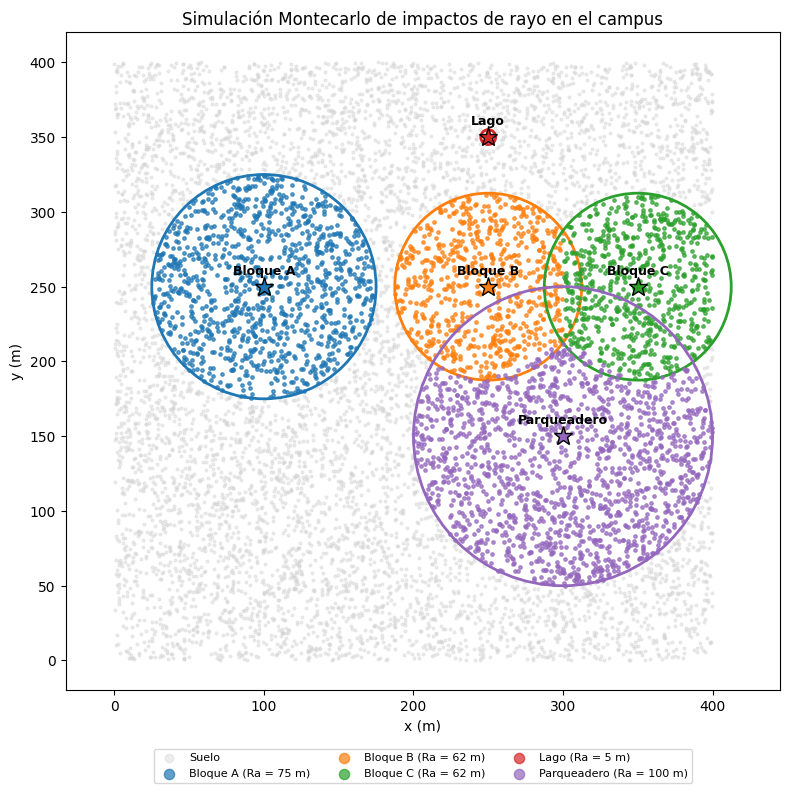

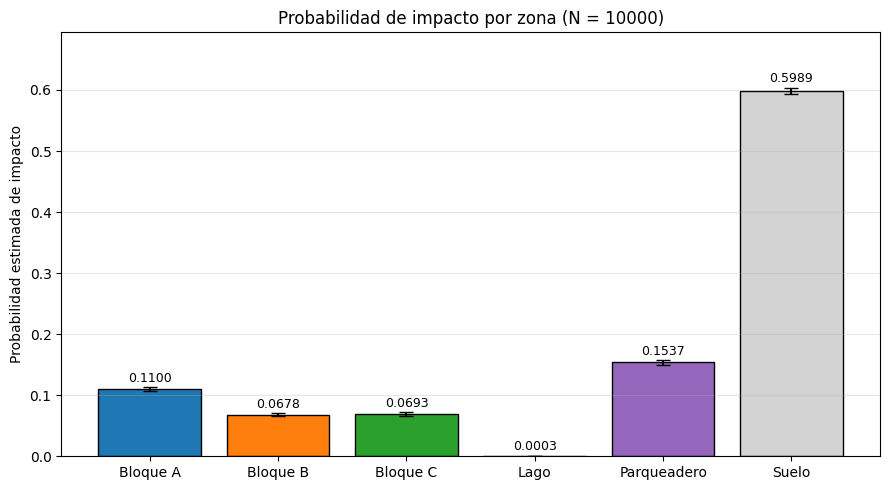


=== VARIACIÓN 1: altura de Bloque A × 2 ===
Ra: 75.0 m -> 150.0 m
P original  = 0.1100
P modificada = 0.3565
Cambio absoluto = +0.2465
Cambio relativo = +224.1 %


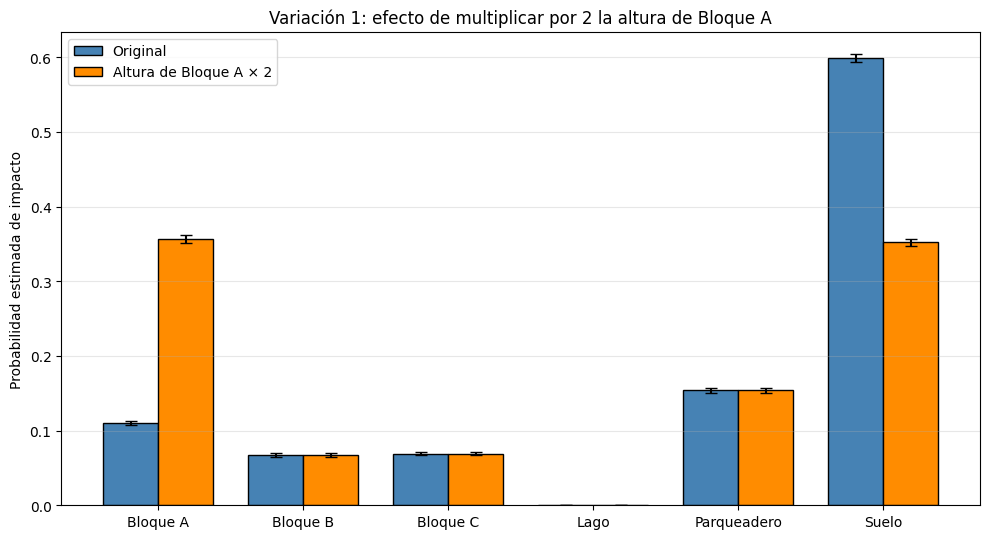


=== VARIACIÓN 2: convergencia de P(Bloque A) ===
       N         P     sigma
     100    0.1400    0.0347
     500    0.0800    0.0121
    1000    0.1140    0.0101
    5000    0.1038    0.0043
   10000    0.1130    0.0032
   50000    0.1104    0.0014


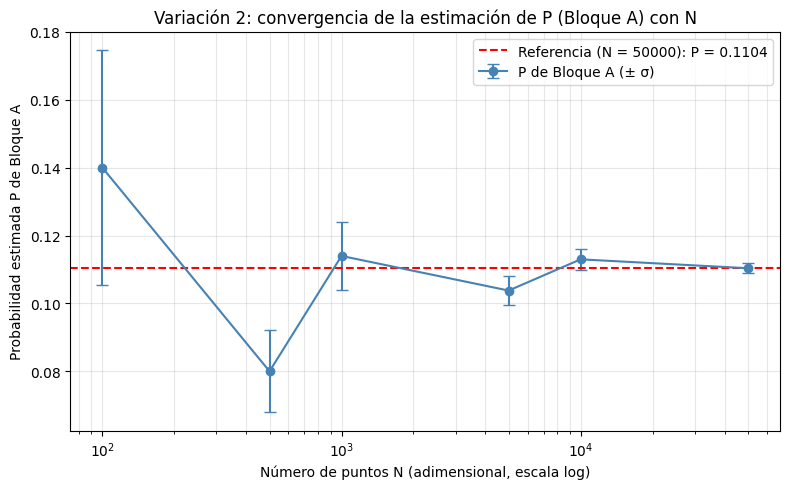

In [3]:
def main():
    # ---------- Simulación principal ----------
    res = simular_montecarlo(LX, LY, ESTRUCTURAS, C_COEF, N_PRINCIPAL, SEMILLA)
    print("=== SIMULACIÓN PRINCIPAL ===")
    imprimir_tabla(res)
    graficar_region(res, LX, LY)      # Gráfica 1
    graficar_barras(res)              # Gráfica 2

    # ---------- Variación 1: duplicar la altura de una estructura ----------
    # Se usa la MISMA semilla: los puntos son idénticos y la diferencia
    # observada se debe únicamente al cambio de altura.
    estructuras_mod = [(n, p, hh * FACTOR_ALTURA if n == ESTRUCTURA_VARIADA else hh)
                       for (n, p, hh) in ESTRUCTURAS]
    res_mod = simular_montecarlo(LX, LY, estructuras_mod, C_COEF, N_PRINCIPAL, SEMILLA)
    k = res["nombres"].index(ESTRUCTURA_VARIADA)
    P0, P1 = res["P"][k], res_mod["P"][k]
    print(f"\n=== VARIACIÓN 1: altura de {ESTRUCTURA_VARIADA} × {FACTOR_ALTURA:g} ===")
    print(f"Ra: {res['Ra'][k]:.1f} m -> {res_mod['Ra'][k]:.1f} m")
    print(f"P original  = {P0:.4f}")
    print(f"P modificada = {P1:.4f}")
    print(f"Cambio absoluto = {P1 - P0:+.4f}")
    print(f"Cambio relativo = {(P1 - P0) / P0 * 100:+.1f} %")
    graficar_comparacion(res, res_mod, ESTRUCTURA_VARIADA, FACTOR_ALTURA)  # Gráfica 3

    # ---------- Variación 2: convergencia con N ----------
    # Se usa una semilla distinta por cada N para que las corridas sean independientes.
    P_conv, sig_conv = [], []
    print(f"\n=== VARIACIÓN 2: convergencia de P({ESTRUCTURA_VARIADA}) ===")
    print(f"{'N':>8}{'P':>10}{'sigma':>10}")
    for j, n in enumerate(N_CONVERGENCIA):
        r = simular_montecarlo(LX, LY, ESTRUCTURAS, C_COEF, n, SEMILLA + j)
        P_conv.append(r["P"][k]); sig_conv.append(r["sigma"][k])
        print(f"{n:>8d}{P_conv[-1]:>10.4f}{sig_conv[-1]:>10.4f}")
    graficar_convergencia(N_CONVERGENCIA, P_conv, sig_conv, ESTRUCTURA_VARIADA)  # Gráfica 4


if __name__ == "__main__":
    main()